<a href="https://colab.research.google.com/github/skrehaman393-ui/CODETECH-Student-Performance-Tracker/blob/main/Movie_Genre_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET CREATED
                                             plot   genre
0        A hero fights criminals to save the city  Action
1        A hero fights criminals to save the city  Action
2    A police officer chases a dangerous criminal  Action
3  Soldiers battle enemies in a dangerous mission  Action
4  Soldiers battle enemies in a dangerous mission  Action

Dataset Shape: (500, 2)

Genre Counts:
genre
Action     100
Comedy     100
Drama      100
Romance    100
Horror     100
Name: count, dtype: int64


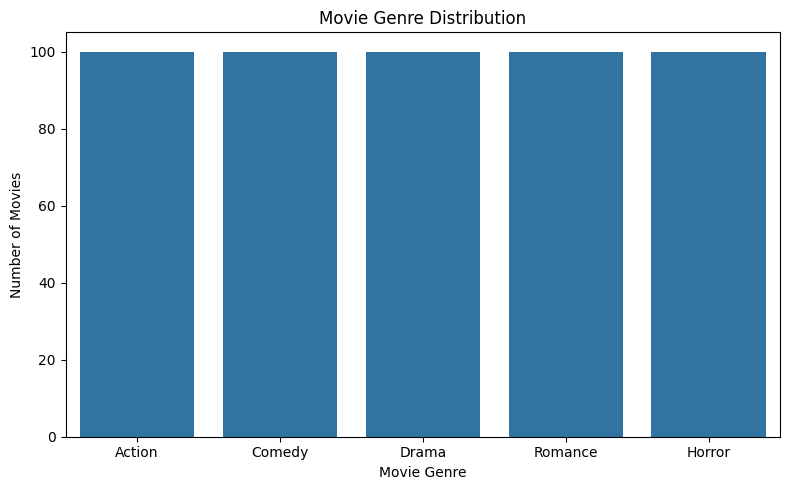


MODEL TRAINED SUCCESSFULLY

Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Action       1.00      1.00      1.00        20
      Comedy       1.00      1.00      1.00        20
       Drama       1.00      1.00      1.00        20
      Horror       1.00      1.00      1.00        20
     Romance       1.00      1.00      1.00        20

    accuracy                           1.00       100
   macro avg       1.00      1.00      1.00       100
weighted avg       1.00      1.00      1.00       100



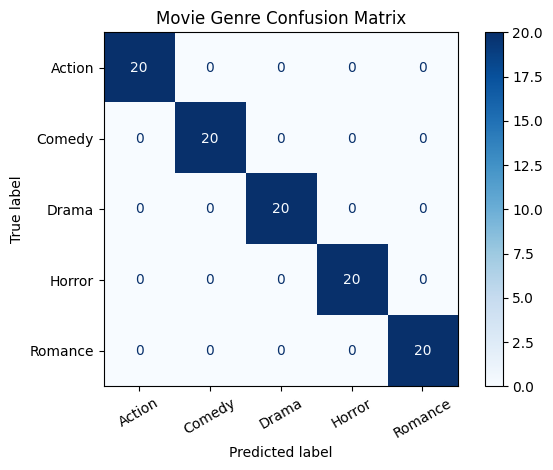


NEW MOVIE PREDICTION
Movie Plot: A brave hero fights criminals to save innocent people
Predicted Genre: Action

TASK 2 COMPLETED SUCCESSFULLY!
Movie_Genre_Results.zip CREATED


In [1]:

# CODETECH INTERNSHIP - TASK 2
# MOVIE GENRE CLASSIFICATION
# Name: Shaik Rehaman

import os
import random
import zipfile
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

random.seed(42)

# Create folders
os.makedirs("Movie_Genre_Project/data", exist_ok=True)
os.makedirs("Movie_Genre_Project/output", exist_ok=True)

# 1. Create sample movie dataset
movies = {
    "Action": [
        "A hero fights criminals to save the city",
        "Soldiers battle enemies in a dangerous mission",
        "A police officer chases a dangerous criminal",
        "A brave fighter rescues people from enemies"
    ],
    "Comedy": [
        "Two friends create funny situations",
        "A family enjoys a hilarious adventure",
        "A comedian makes everyone laugh",
        "A student gets into funny trouble"
    ],
    "Drama": [
        "A family faces emotional problems",
        "A teacher helps students achieve success",
        "A musician struggles in life",
        "A young man overcomes family difficulties"
    ],
    "Romance": [
        "Two people fall in love",
        "A couple builds a beautiful relationship",
        "Childhood friends discover true love",
        "A romantic story about a young couple"
    ],
    "Horror": [
        "Friends discover a haunted house",
        "A ghost frightens a family",
        "A mysterious creature appears at night",
        "A scary story inside an abandoned building"
    ]
}

data = []

for genre, plots in movies.items():
    for i in range(100):
        plot = random.choice(plots)
        data.append([plot, genre])

df = pd.DataFrame(data, columns=["plot", "genre"])

# Save dataset
df.to_csv(
    "Movie_Genre_Project/data/movie_dataset.csv",
    index=False
)

print("DATASET CREATED")
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nGenre Counts:")
print(df["genre"].value_counts())

# 2. Genre distribution graph
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="genre")
plt.title("Movie Genre Distribution")
plt.xlabel("Movie Genre")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig("Movie_Genre_Project/output/genre_distribution.png")
plt.show()

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    df["plot"],
    df["genre"],
    test_size=0.2,
    random_state=42,
    stratify=df["genre"]
)

# 4. Create machine learning model
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# 5. Train model
model.fit(X_train, y_train)

print("\nMODEL TRAINED SUCCESSFULLY")

# 6. Predictions
predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, predictions))

# Save evaluation
pd.DataFrame({
    "Accuracy": [accuracy]
}).to_csv(
    "Movie_Genre_Project/output/model_evaluation.csv",
    index=False
)

# 7. Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    xticks_rotation=30,
    cmap="Blues"
)

plt.title("Movie Genre Confusion Matrix")
plt.tight_layout()
plt.savefig("Movie_Genre_Project/output/confusion_matrix.png")
plt.show()

# 8. Test new movie plot
new_movie = [
    "A brave hero fights criminals to save innocent people"
]

result = model.predict(new_movie)

print("\nNEW MOVIE PREDICTION")
print("Movie Plot:", new_movie[0])
print("Predicted Genre:", result[0])

# Save prediction
pd.DataFrame({
    "Movie Plot": new_movie,
    "Predicted Genre": result
}).to_csv(
    "Movie_Genre_Project/output/prediction_results.csv",
    index=False
)

# 9. Save trained model
joblib.dump(
    model,
    "Movie_Genre_Project/output/movie_genre_model.pkl"
)

# 10. Save classification report
report = classification_report(
    y_test, predictions, output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    "Movie_Genre_Project/output/classification_report.csv"
)

# 11. Create ZIP file
with zipfile.ZipFile(
    "Movie_Genre_Results.zip", "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for root, dirs, files in os.walk("Movie_Genre_Project"):
        for file in files:
            path = os.path.join(root, file)
            zip_file.write(path)

print("\nTASK 2 COMPLETED SUCCESSFULLY!")
print("Movie_Genre_Results.zip CREATED")